# Employee Resignation Prediction

## Progress Review I — Viva Evidence Notebook

**Student ID:** IT25100445  
**Contribution:** Feature Selection and Redundancy Analysis

This notebook provides individual viva evidence for the preprocessing and exploratory data analysis (EDA) contribution. It is not the final model pipeline. It follows the project's frozen feature contract, and all feature-selection and redundancy checks are based only on the development partition. The formal holdout is not used to make feature-selection decisions.

In [11]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display


# Keep tabular output concise and readable during the viva.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 25)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)

# Use a consistent, readable plotting style for later evidence.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})


def find_project_root(start_path: Path) -> Path:
    """Find the repository root from the current working directory."""
    for candidate in (start_path, *start_path.parents):
        required_markers = (
            candidate / "README.md",
            candidate / "configs" / "feature_contract.yaml",
            candidate / "notebooks",
        )
        if all(marker.exists() for marker in required_markers):
            return candidate

    raise FileNotFoundError(
        "Repository root could not be located from the current working directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())

RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)
SPLIT_REGISTRY_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"

assert RAW_DATA_PATH.is_file(), f"Raw dataset not found: {RAW_DATA_PATH}"
assert SPLIT_REGISTRY_PATH.is_file(), f"Split registry not found: {SPLIT_REGISTRY_PATH}"
assert FEATURE_CONTRACT_PATH.is_file(), f"Feature contract not found: {FEATURE_CONTRACT_PATH}"

print("Project root detected:", PROJECT_ROOT)
print("Required project files found: raw dataset, split registry, feature contract")


Project root detected: C:\Users\Kawya\Documents\AIML Project
Required project files found: raw dataset, split registry, feature contract


In [2]:
# Load and Verify Development Data

EXPECTED_RAW_SHA256 = (
    "2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb"
)
EXPECTED_SPLIT_SHA256 = (
    "87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41"
)


def calculate_sha256(file_path: Path) -> str:
    """Calculate a file's SHA-256 checksum without changing the file."""
    digest = hashlib.sha256()
    with file_path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


raw_sha256 = calculate_sha256(RAW_DATA_PATH)
split_sha256 = calculate_sha256(SPLIT_REGISTRY_PATH)

assert raw_sha256 == EXPECTED_RAW_SHA256, "Raw dataset checksum mismatch."
assert split_sha256 == EXPECTED_SPLIT_SHA256, "Split registry checksum mismatch."

raw_df = pd.read_csv(RAW_DATA_PATH)
split_registry = pd.read_csv(
    SPLIT_REGISTRY_PATH,
    dtype={"cv_fold": "Int64"},
)

assert raw_df.shape == (100_000, 20), f"Unexpected raw shape: {raw_df.shape}"
assert "Employee_ID" in raw_df.columns, "Employee_ID is missing from the raw data."
assert raw_df["Employee_ID"].is_unique, "Raw Employee_ID values must be unique."

required_registry_columns = ["Employee_ID", "partition", "cv_fold"]
assert split_registry.columns.tolist() == required_registry_columns, (
    f"Unexpected split-registry columns: {split_registry.columns.tolist()}"
)
assert len(split_registry) == 100_000, "Split registry must contain 100,000 rows."
assert split_registry["Employee_ID"].is_unique, (
    "Split-registry Employee_ID values must be unique."
)

partition_counts = split_registry["partition"].value_counts()
assert set(partition_counts.index) == {"development", "holdout"}, (
    f"Unexpected partition labels: {sorted(partition_counts.index.tolist())}"
)
assert partition_counts["development"] == 80_000
assert partition_counts["holdout"] == 20_000

development_registry = split_registry.loc[
    split_registry["partition"].eq("development")
].copy()
holdout_registry = split_registry.loc[
    split_registry["partition"].eq("holdout")
].copy()

assert development_registry["cv_fold"].notna().all(), (
    "Every development record must have a cv_fold assignment."
)
assert holdout_registry["cv_fold"].isna().all(), (
    "Formal-holdout records must not have development-fold assignments."
)

development_fold_counts = (
    development_registry["cv_fold"]
    .value_counts()
    .sort_index()
)
assert development_fold_counts.index.astype(int).tolist() == [1, 2, 3, 4, 5]
assert development_fold_counts.astype(int).tolist() == [16_000] * 5

merged_df = raw_df.merge(
    split_registry,
    on="Employee_ID",
    how="left",
    validate="one_to_one",
    indicator=True,
)
assert len(merged_df) == 100_000, "Merged data must contain 100,000 rows."
assert merged_df["_merge"].eq("both").all(), (
    "Every raw Employee_ID must match exactly one split-registry record."
)
merged_df = merged_df.drop(columns="_merge")

development_df = (
    merged_df.loc[merged_df["partition"].eq("development")]
    .copy()
    .reset_index(drop=True)
)
assert len(development_df) == 80_000, (
    "Development analysis data must contain 80,000 rows."
)

formal_holdout_ids = set(holdout_registry["Employee_ID"])
development_ids = set(development_df["Employee_ID"])
holdout_overlap_count = len(development_ids.intersection(formal_holdout_ids))
assert holdout_overlap_count == 0, (
    "Formal-holdout Employee_ID values were found in the development analysis data."
)

print(f"Raw data: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
print(f"Development records: {len(development_df):,}")
print(f"Formal holdout records: {len(formal_holdout_ids):,}")
print("Development folds: 5 × 16,000")
print(f"Holdout overlap in analysis data: {holdout_overlap_count}")
print("Raw checksum: VERIFIED")
print("Split-registry checksum: VERIFIED")


Raw data: 100,000 rows × 20 columns
Development records: 80,000
Formal holdout records: 20,000
Development folds: 5 × 16,000
Holdout overlap in analysis data: 0
Raw checksum: VERIFIED
Split-registry checksum: VERIFIED


In [3]:
# Define Frozen Feature Roles

with FEATURE_CONTRACT_PATH.open("r", encoding="utf-8") as file_handle:
    feature_contract = yaml.safe_load(file_handle)

target_column = feature_contract["target"]["column"]
categorical_columns = [
    feature["name"] for feature in feature_contract["categorical_features"]
]
numerical_columns = [
    feature["name"] for feature in feature_contract["numerical_features"]
]
input_columns = list(feature_contract["primary_model_features"])

assert target_column == "Resigned"
assert len(categorical_columns) == 4
assert len(numerical_columns) == 13
assert len(input_columns) == 17
assert categorical_columns + numerical_columns == input_columns, (
    "Feature groups do not match the frozen primary feature order."
)

print(f"Target variable: {target_column}")
print(f"Categorical predictors ({len(categorical_columns)}): {categorical_columns}")
print(f"Numerical/ordinal predictors ({len(numerical_columns)}): {numerical_columns}")
print(f"Total approved predictors: {len(input_columns)}")


Target variable: Resigned
Categorical predictors (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
Numerical/ordinal predictors (13): ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
Total approved predictors: 17


In [4]:
# Excluded Columns

excluded_column_names = ["Employee_ID", "Hire_Date", "Resigned"]
excluded_columns = pd.DataFrame(
    {
        "column": excluded_column_names,
        "reason": [
            (
                "Unique record identifier used for traceability and split alignment, "
                "not a meaningful predictor."
            ),
            (
                "Audit-only raw date representation. The project retains "
                "Years_At_Company as the approved tenure predictor because Hire_Date "
                "is strongly redundant with that representation."
            ),
            (
                "Prediction target. Including it in X would create direct target leakage."
            ),
        ],
    }
)

assert set(excluded_column_names).isdisjoint(input_columns), (
    "An excluded column appears in the frozen predictor list."
)

display(excluded_columns)


,column,reason
0,Employee_ID,"Unique record identifier used for traceability and split alignment, not a me..."
1,Hire_Date,Audit-only raw date representation. The project retains Years_At_Company as ...
2,Resigned,Prediction target. Including it in X would create direct target leakage.


In [5]:
# Create Final Predictor Matrix X and Target y

X = development_df[input_columns].copy()
y = development_df[target_column].astype(int).copy()

assert X.shape == (80_000, 17), f"Unexpected X shape: {X.shape}"
assert len(y) == 80_000, f"Unexpected y length: {len(y)}"
assert "Employee_ID" not in X.columns
assert "Hire_Date" not in X.columns
assert "Resigned" not in X.columns

print(f"Predictor matrix X: {X.shape[0]:,} rows × {X.shape[1]} columns")
print(f"Target vector y: {len(y):,} rows, stored separately")
print("Frozen predictors only: VERIFIED")
print("Excluded columns absent from X: VERIFIED")


Predictor matrix X: 80,000 rows × 17 columns
Target vector y: 80,000 rows, stored separately
Frozen predictors only: VERIFIED
Excluded columns absent from X: VERIFIED


In [6]:
# Predictor Inventory

categorical_set = set(categorical_columns)
predictor_inventory = pd.DataFrame(
    {
        "number": range(1, len(input_columns) + 1),
        "feature": input_columns,
        "feature_type": [
            "Categorical"
            if feature in categorical_set
            else "Numerical/Ordinal"
            for feature in input_columns
        ],
    }
)

assert X.columns.tolist() == input_columns, (
    "X column order does not match the frozen feature contract."
)
assert (predictor_inventory["feature_type"] == "Categorical").sum() == 4
assert (predictor_inventory["feature_type"] == "Numerical/Ordinal").sum() == 13
assert len(predictor_inventory) == 17

print(f"X shape: {X.shape}")
print(f"Categorical predictors: {len(categorical_columns)}")
print(f"Numerical/ordinal predictors: {len(numerical_columns)}")
print(f"Total predictors: {len(input_columns)}")
display(predictor_inventory)


X shape: (80000, 17)
Categorical predictors: 4
Numerical/ordinal predictors: 13
Total predictors: 17


,number,feature,feature_type
0,1,Department,Categorical
1,2,Gender,Categorical
2,3,Job_Title,Categorical
3,4,Education_Level,Categorical
4,5,Age,Numerical/Ordinal
5,6,Years_At_Company,Numerical/Ordinal
6,7,Performance_Score,Numerical/Ordinal
7,8,Monthly_Salary,Numerical/Ordinal
8,9,Work_Hours_Per_Week,Numerical/Ordinal
9,10,Projects_Handled,Numerical/Ordinal


In [7]:
# Development-Only Tenure Redundancy Audit

# Reuse the parsing and derivation logic from the shared data-audit notebook.
development_hire_dates = pd.to_datetime(
    development_df["Hire_Date"],
    errors="coerce",
)
invalid_hire_date_count = int(development_hire_dates.isna().sum())
assert invalid_hire_date_count == 0, (
    f"Development data contains {invalid_hire_date_count} invalid Hire_Date values."
)

tenure_anchor_date = development_hire_dates.max()
derived_tenure = (
    (tenure_anchor_date - development_hire_dates).dt.days / 365.25
).astype(int)
tenure_difference = (
    derived_tenure - development_df["Years_At_Company"]
).abs()

development_record_count = len(development_df)
exact_agreement_count = int(tenure_difference.eq(0).sum())
within_one_year_count = int(tenure_difference.le(1).sum())
exact_agreement_percentage = (
    exact_agreement_count / development_record_count * 100
)
within_one_year_percentage = (
    within_one_year_count / development_record_count * 100
)

tenure_redundancy_summary = pd.DataFrame(
    {
        "measure": [
            "Total development records",
            "Exact tenure agreement",
            "Agreement within one year",
        ],
        "count": [
            development_record_count,
            exact_agreement_count,
            within_one_year_count,
        ],
        "percentage": [
            100.0,
            exact_agreement_percentage,
            within_one_year_percentage,
        ],
    }
)

assert "derived_tenure" not in X.columns
assert X.columns.tolist() == input_columns

display(tenure_redundancy_summary.style.format({"count": "{:,.0f}", "percentage": "{:.2f}%"}))
print("Hire_Date is used only for redundancy and audit evidence.")
print("Years_At_Company remains the approved tenure predictor.")
print("The derived tenure value is not added to the predictor matrix.")


,measure,count,percentage
0,Total development records,"80,000",100.00%
1,Exact tenure agreement,"79,415",99.27%
2,Agreement within one year,"80,000",100.00%


Hire_Date is used only for redundancy and audit evidence.
Years_At_Company remains the approved tenure predictor.
The derived tenure value is not added to the predictor matrix.


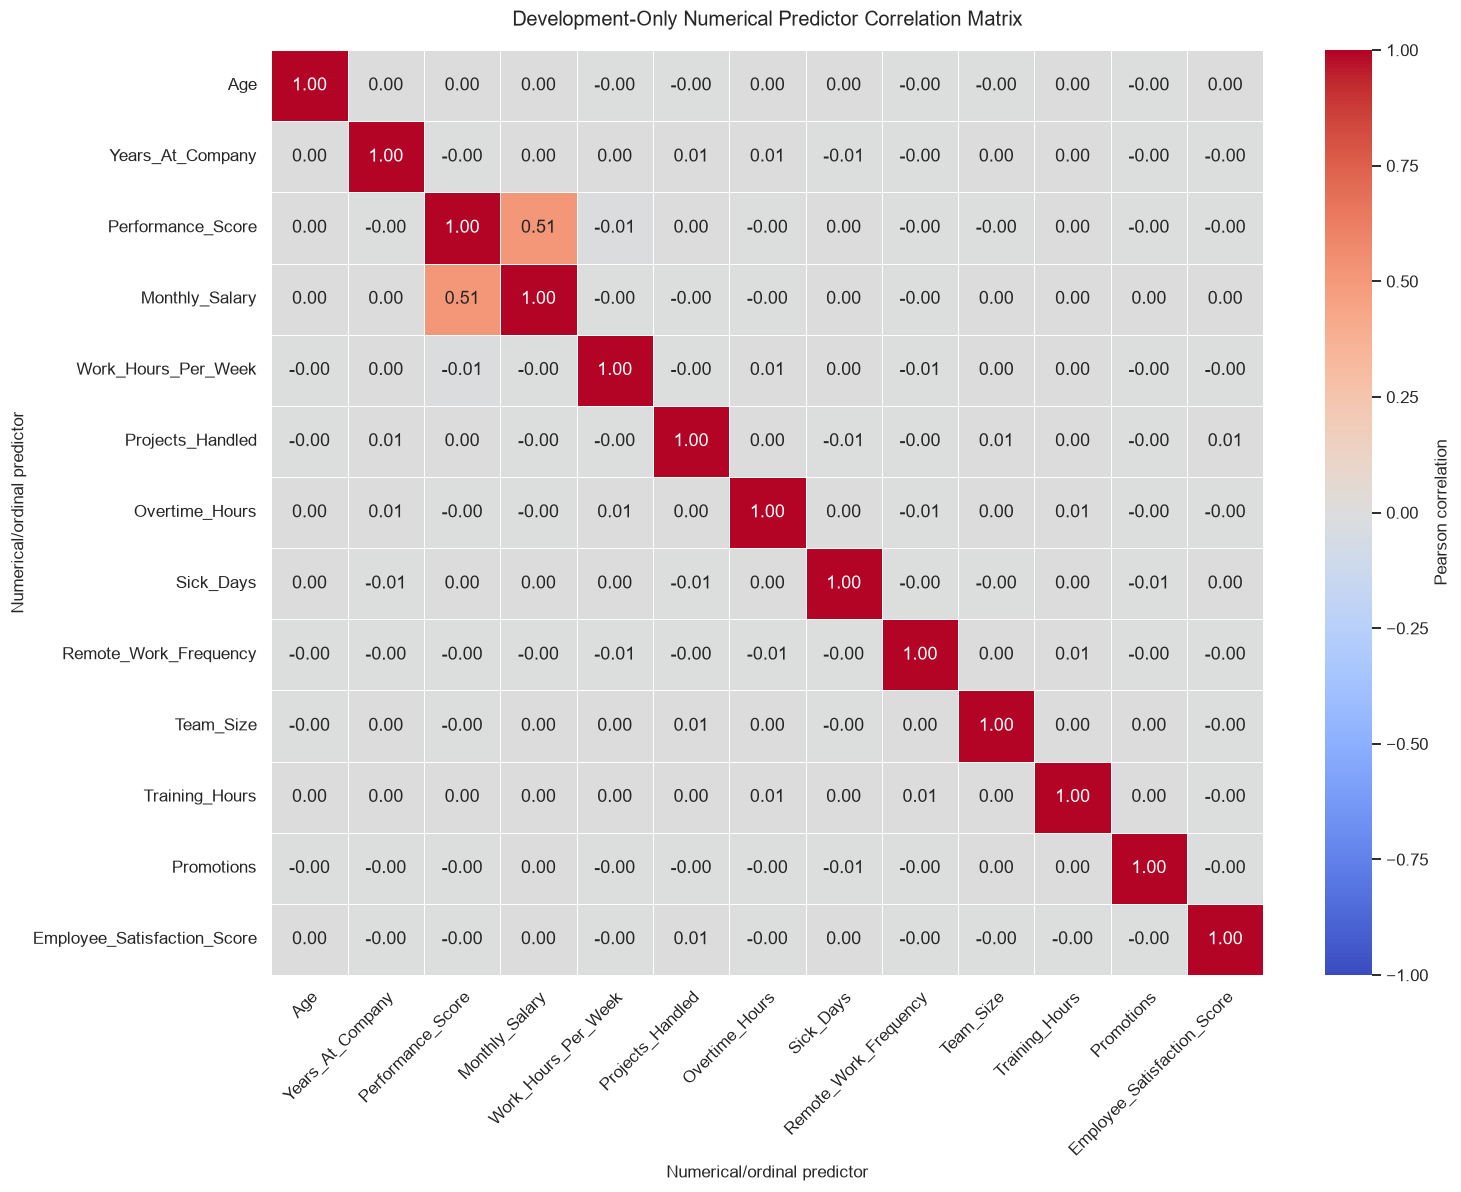

Strongest absolute off-diagonal correlation: Performance_Score and Monthly_Salary (Pearson correlation = 0.5100)


In [8]:
# Numerical Correlation Heatmap

numerical_development_df = development_df[numerical_columns]
correlation_matrix = numerical_development_df.corr(method="pearson")

assert numerical_development_df.columns.tolist() == numerical_columns
assert correlation_matrix.shape == (13, 13)
assert correlation_matrix.index.tolist() == numerical_columns
assert correlation_matrix.columns.tolist() == numerical_columns
assert {"Employee_ID", "Hire_Date", "Resigned"}.isdisjoint(
    correlation_matrix.columns
)

upper_triangle_mask = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1,
)
upper_triangle = correlation_matrix.where(upper_triangle_mask)
strongest_feature_1, strongest_feature_2 = (
    upper_triangle.abs().stack().idxmax()
)
strongest_correlation = correlation_matrix.loc[
    strongest_feature_1, strongest_feature_2
]

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Development-Only Numerical Predictor Correlation Matrix", pad=16)
ax.set_xlabel("Numerical/ordinal predictor")
ax.set_ylabel("Numerical/ordinal predictor")
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor",
)
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

print(
    "Strongest absolute off-diagonal correlation: "
    f"{strongest_feature_1} and {strongest_feature_2} "
    f"(Pearson correlation = {strongest_correlation:.4f})"
)


## Correlation and Redundancy Interpretation

- **Tenure redundancy:** On the 80,000-row development partition, tenure derived with the existing project audit method agrees exactly with `Years_At_Company` for 79,415 records (99.27%). All 80,000 records are within one year. The representations are therefore strongly redundant, but not mathematically identical. Raw `Hire_Date` remains audit-only, while `Years_At_Company` remains the approved tenure predictor.
- **Correlation result:** The strongest numerical predictor-to-predictor Pearson correlation is the moderate positive association between `Performance_Score` and `Monthly_Salary` ($r = 0.5100$). This is an association and does not establish causation.
- **Feature-selection decision:** Correlation is evidence for redundancy review, not an automatic deletion rule. Neither variable is removed solely because of this correlation, so the frozen 17-feature contract remains unchanged.

## Feature Selection vs PCA and Correlation vs Causation

- **Feature selection** retains or removes original variables. This notebook preserves the project's 17 approved original predictors.
- **Principal Component Analysis (PCA)** creates new transformed components from combinations of original numerical variables. PCA is handled separately in the project and does not redefine this notebook's frozen predictor set.
- **Correlation** measures statistical association; it does not prove that one variable causes another and must not be interpreted as evidence of a causal resignation driver.

> **Viva contrast:** Feature selection decides which original columns remain in `X`, while PCA replaces original numerical dimensions with transformed components.

In [9]:
# Final Verification and Viva Conclusion

assert X.shape == (80_000, 17)
assert len(categorical_columns) == 4
assert len(numerical_columns) == 13
assert len(input_columns) == 17
assert list(X.columns) == list(input_columns)
assert "Employee_ID" not in X.columns
assert "Hire_Date" not in X.columns
assert "Resigned" not in X.columns
assert target_column == "Resigned"
assert len(y) == 80_000
assert y.index.equals(X.index)
assert len(development_df) == 80_000

final_holdout_overlap = len(
    set(development_df["Employee_ID"]).intersection(formal_holdout_ids)
)
assert final_holdout_overlap == 0

assert {strongest_feature_1, strongest_feature_2} == {
    "Performance_Score",
    "Monthly_Salary",
}
assert np.isclose(
    strongest_correlation,
    correlation_matrix.loc[strongest_feature_1, strongest_feature_2],
)
assert round(float(strongest_correlation), 4) == 0.5100

assert exact_agreement_count == 79_415
assert within_one_year_count == 80_000

final_verification = pd.DataFrame(
    {
        "item": [
            "Approved predictors",
            "Categorical",
            "Numerical/ordinal",
            "Excluded from X",
            "Development records analyzed",
            "Formal holdout records analyzed",
            "Tenure exact agreement",
            "Tenure within one year",
            "Strongest numerical predictor correlation",
            "Pearson r",
            "Target leakage",
            "Final decision",
        ],
        "verified_result": [
            str(len(input_columns)),
            str(len(categorical_columns)),
            str(len(numerical_columns)),
            "Employee_ID, Hire_Date, Resigned",
            f"{len(development_df):,}",
            "0",
            (
                f"{exact_agreement_count:,} / {development_record_count:,} "
                f"({exact_agreement_percentage:.2f}%)"
            ),
            (
                f"{within_one_year_count:,} / {development_record_count:,} "
                f"({within_one_year_percentage:.2f}%)"
            ),
            f"{strongest_feature_1} ↔ {strongest_feature_2}",
            f"{strongest_correlation:.4f}",
            "None detected",
            "Frozen 17-feature contract retained",
        ],
    }
)

print("Progress Review I — Member 5 Final Verification")
display(final_verification)

print(
    "Viva conclusion: The final predictor matrix contains the 17 frozen project "
    "predictors: four categorical and thirteen numerical/ordinal. Employee_ID "
    "is excluded as an identifier, raw Hire_Date is retained only for audit "
    "evidence because it is strongly redundant with Years_At_Company, and "
    "Resigned is stored separately as the target to prevent leakage. "
    "Development-only correlation analysis identified a moderate positive "
    "association between Performance_Score and Monthly_Salary "
    f"(r = {strongest_correlation:.4f}), but correlation alone was not used to "
    "remove an approved predictor. No formal-holdout records influenced these "
    "feature-selection decisions."
)


Progress Review I — Member 5 Final Verification


,item,verified_result
0,Approved predictors,17
1,Categorical,4
2,Numerical/ordinal,13
3,Excluded from X,"Employee_ID, Hire_Date, Resigned"
4,Development records analyzed,"80,000"
5,Formal holdout records analyzed,0
6,Tenure exact agreement,"79,415 / 80,000 (99.27%)"
7,Tenure within one year,"80,000 / 80,000 (100.00%)"
8,Strongest numerical predictor correlation,Performance_Score ↔ Monthly_Salary
9,Pearson r,0.5100


Viva conclusion: The final predictor matrix contains the 17 frozen project predictors: four categorical and thirteen numerical/ordinal. Employee_ID is excluded as an identifier, raw Hire_Date is retained only for audit evidence because it is strongly redundant with Years_At_Company, and Resigned is stored separately as the target to prevent leakage. Development-only correlation analysis identified a moderate positive association between Performance_Score and Monthly_Salary (r = 0.5100), but correlation alone was not used to remove an approved predictor. No formal-holdout records influenced these feature-selection decisions.
